# EDA отзывов

Посмотрим исходные отзывы, уберём повторы и соберём рабочую выборку с одинаковым числом записей каждого класса.

In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'config.yaml').is_file()
)
config = yaml.safe_load((ROOT / 'config.yaml').read_text(encoding='utf-8'))
settings = config['datasets']['reviews']

SEED = config['seed']
TARGET_SIZE = settings['target_size']
LABELS = settings['label_names']
CLASS_ORDER = list(LABELS.values())
SPLIT_RATIOS = pd.Series(settings['split_ratios'], dtype=float)
SPLITS = list(SPLIT_RATIOS.index)
PREVIEW_SIZE = settings['preview_per_class']
RAW_DIR = ROOT / settings['raw_dir']
PROCESSED_DIR = ROOT / settings['processed_dir']

pd.set_option('display.max_colwidth', None)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

Matplotlib is building the font cache; this may take a moment.


In [2]:
frames = []
for split in SPLITS:
    frame = pd.read_json(RAW_DIR / f'{split}.jsonl', lines=True, dtype={'id': 'string'})
    frames.append(frame.assign(split=split))

df = pd.concat(frames, ignore_index=True)
df['split'] = pd.Categorical(df['split'], categories=SPLITS, ordered=True)

In [3]:
def show_examples(frame):
    examples = pd.concat([
        frame.loc[frame['label'].eq(label)].sample(n=PREVIEW_SIZE, random_state=SEED)
        for label in LABELS
    ], ignore_index=True)
    display(examples[['label_text', 'text']].rename(columns={'label_text': 'Метка', 'text': 'Отзыв'}))


show_examples(df)

,Метка,Отзыв
0,negative,"Ужасный просто...широкий...на свой 42 заказала размер S, как-будто размер 48...\nткань вообще не костюмная, весь электризуется, очень тонкий!"
1,negative,"Так и не пришел товар! Не успела продлить ожидание, так что и без денег осталась!"
2,neutral,резинка очень тугая перетягивает ногу
3,neutral,"Получила заказ в течение месяца, качество нормальное, резинка, все тянется, ношу 48 заказывала xl сел хорошо, но эффект не такой как ожидала, утягивает не очень хорошо, эффект не такой как в описании."
4,positive,"платье только слегка мало, поэтому на такие же параметры (и при наличии плоского живота,если вам повезло больше,чем мне) вполне можно заказать :)"
5,positive,"Nice skirt, material is good, appropriate length. Absolutely universal, can be worn with any top. I am very happy with it."


In [4]:
def count_classes(frame):
    counts = pd.crosstab(frame['split'], frame['label_text'])
    return counts.reindex(index=SPLITS, columns=CLASS_ORDER, fill_value=0)


source_counts = count_classes(df)
display(
    source_counts.assign(Всего=source_counts.sum(axis=1))
    .rename_axis(index='Выборка', columns='Класс')
)

Класс,negative,neutral,positive,Всего
Выборка,,,,
train,15000,15000,15000,45000
validation,5000,5000,5000,15000
test,5000,5000,5000,15000


## Чистим отзывы

В исходных данных встречаются английские отзывы и размеры вроде xl. Оставляем отзывы с русскими буквами без латиницы.

Дубли сравниваем через strip().lower(). Если метки отличаются, убираем всю группу. Если совпадают, оставляем первую запись. Сам текст не меняем.

In [5]:
df['text_key'] = df['text'].str.strip().str.lower()
non_empty = df.loc[df['text_key'].notna() & df['text_key'].ne('')]

has_cyrillic = non_empty['text'].str.contains(r'[А-Яа-яЁё]', na=False)
has_latin = non_empty['text'].str.contains(r'[A-Za-z]', na=False)
russian = non_empty.loc[has_cyrillic & ~has_latin]

label_counts = non_empty.groupby('text_key')['label'].nunique()
conflict_keys = label_counts.index[label_counts.gt(1)]
consistent = russian.loc[~russian['text_key'].isin(conflict_keys)]
clean_df = consistent.drop_duplicates('text_key', keep='first').copy()

removed = pd.Series({
    'Пустой текст': len(df) - len(non_empty),
    'Фильтр букв': len(non_empty) - len(russian),
    'Дубли с разными метками': len(russian) - len(consistent),
    'Дубли с одинаковой меткой': len(consistent) - len(clean_df),
}, name='Убрано')
display(removed.to_frame())

,Убрано
Пустой текст,1
Фильтр букв,12418
Дубли с разными метками,366
Дубли с одинаковой меткой,430


## Собираем рабочий набор

Берём поровну отзывов каждого класса из исходных train, validation и test. Размер набора, доли и seed берём из конфига.

In [6]:
per_class = TARGET_SIZE // len(LABELS)
split_sizes = (SPLIT_RATIOS * per_class).round().astype(int)

rng = np.random.default_rng(SEED)
parts = []
for split in SPLITS:
    for label in LABELS:
        pool = clean_df.loc[
            clean_df['split'].eq(split) & clean_df['label'].eq(label)
        ].sort_values('id')
        parts.append(pool.sample(n=int(split_sizes[split]), random_state=rng))

working_df = (
    pd.concat(parts, ignore_index=True)
    .sort_values(['split', 'label', 'id'])
    .reset_index(drop=True)
)
working_counts = count_classes(working_df)
display(
    working_counts.assign(Всего=working_counts.sum(axis=1))
    .rename_axis(index='Выборка', columns='Класс')
)

Класс,negative,neutral,positive,Всего
Выборка,,,,
train,600,600,600,1800
validation,200,200,200,600
test,200,200,200,600


## Что получилось

Посмотрим примеры из рабочего набора и сравним доли классов до очистки, после неё и после отбора.

In [7]:
show_examples(working_df)

,Метка,Отзыв
0,negative,"шорты кривые,одна половина больше другой ,маломерят очень,"
1,negative,"товар не пришел,открыла спор,спор закрыли с решением вернуть мне деньги,но прошел уже месяц,деньги так и не вернули.полтыщи на ветер."
2,neutral,"Куртка отдаленно напоминает то, что изображено на фото продавца. Во-первых, по низу куртки вшита резинка, поэтому силуэт не приталенный, а скорее бочкообразный. Во-вторых, ужасная фурнитура: центральная молния ""под серебро"", а бегунки -""под золото"" и не такие, как на фото продавца. Выглядит ужасно. Наполнитель расположен в куртке не равномерно, буграми. Воротник искусственный, а не натуральный, как было обещано и пришит он на белую! подкладку, притом, что куртка сама черная. Внутренние карманы разного размера. Доставка заняла 45дней из них судя по трекингу большую часть времени посылка плутала по просторам Китая.Покупкой совершенно не довольна."
3,neutral,"Оооочень неаккуратная опушка капюшона, виден целый пласт материала, на котором закреплен мех - полный провал. Местами пуховик сидит кривовато."
4,positive,"хорошие, теплые"
5,positive,СПАСИБО!!!


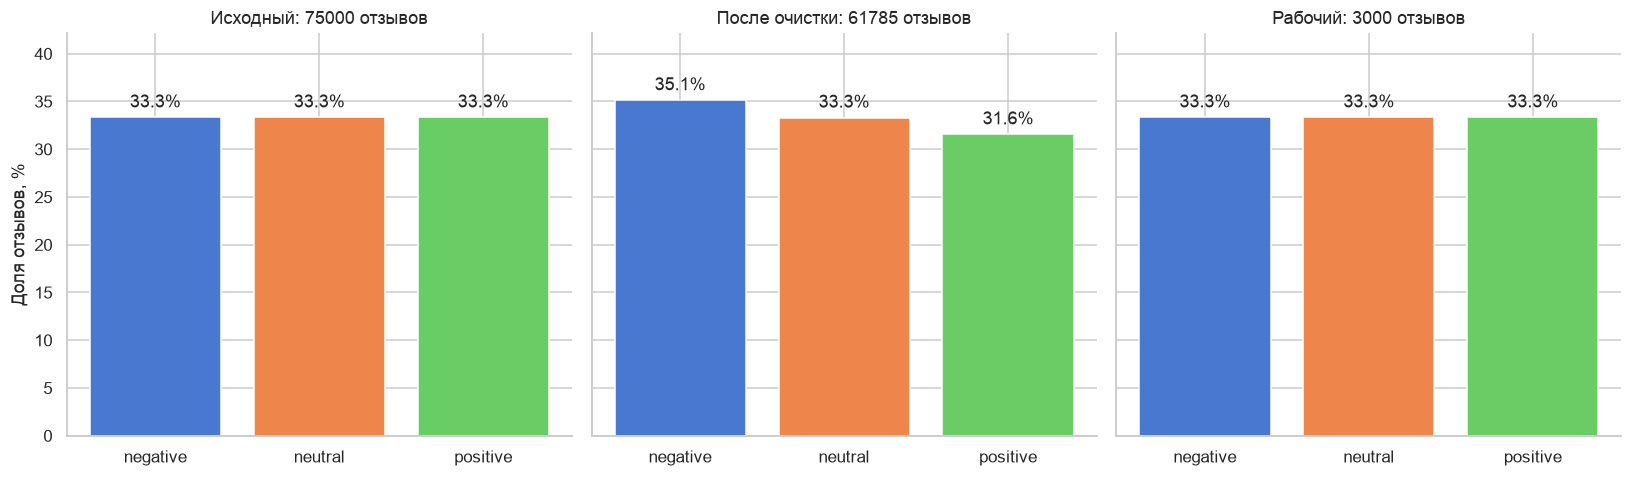

In [8]:
stages = {'Исходный': df, 'После очистки': clean_df, 'Рабочий': working_df}
colors = sns.color_palette('muted', len(CLASS_ORDER))
fig, axes = plt.subplots(1, len(stages), figsize=(15, 4.5), sharey=True)

for ax, (name, frame) in zip(axes, stages.items()):
    shares = frame['label_text'].value_counts(normalize=True).reindex(CLASS_ORDER) * 100
    bars = ax.bar(CLASS_ORDER, shares, color=colors)
    ax.bar_label(bars, labels=[f'{share:.1f}%' for share in shares], padding=4)
    ax.set_title(f'{name}: {len(frame)} отзывов')
    ax.margins(y=0.2)

axes[0].set_ylabel('Доля отзывов, %')
fig.tight_layout()
plt.show()

После очистки positive осталось меньше, чем negative. В рабочий набор взяли поровну отзывов каждого класса.

Метки оставляем исходные. Фильтр букв и удаление дублей не проверяют смысл отзыва.

## Сохраняем данные

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

data_columns = ['id', 'text', 'label', 'label_text']
for split in SPLITS:
    split_data = working_df.loc[working_df['split'].eq(split), data_columns]
    split_data.to_json(
        PROCESSED_DIR / f'{split}.jsonl',
        orient='records', lines=True, force_ascii=False,
    )

print(f'Сохранено отзывов: {len(working_df)}')

Сохранено отзывов: 3000
